In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
#%matplotlib inline

In [40]:
# Read CSV file to load data
df = pd.read_csv('Dataset_Transformation.csv', sep=';')
df

,Color,Size,Label
0,Black,S,1
1,White,L,0
2,Black,M,0
3,Black,M,1
4,Red,L,1
5,White,L,1
6,Black,S,0
7,Red,M,1
8,Black,L,0
9,Red,S,0


# One Hot Encoding

In [41]:
#one hot encoding of color, leave out one category to avoid dummy variable trap
color_oh_encoded = pd.get_dummies(df['Color'], prefix='Color', drop_first=True)
color_oh_encoded

,Color_Red,Color_White
0,False,False
1,False,True
2,False,False
3,False,False
4,True,False
5,False,True
6,False,False
7,True,False
8,False,False
9,True,False


In [42]:
#transform false/true values to 0/1
color_oh_encoded = color_oh_encoded.astype(int)
color_oh_encoded 

,Color_Red,Color_White
0,0,0
1,0,1
2,0,0
3,0,0
4,1,0
5,0,1
6,0,0
7,1,0
8,0,0
9,1,0


In [43]:
#join new features to original data frame
df.join(color_oh_encoded, lsuffix='_df', rsuffix='_df2')

,Color,Size,Label,Color_Red,Color_White
0,Black,S,1,0,0
1,White,L,0,0,1
2,Black,M,0,0,0
3,Black,M,1,0,0
4,Red,L,1,1,0
5,White,L,1,0,1
6,Black,S,0,0,0
7,Red,M,1,1,0
8,Black,L,0,0,0
9,Red,S,0,1,0


# Target Encoding

In [44]:
df

,Color,Size,Label
0,Black,S,1
1,White,L,0
2,Black,M,0
3,Black,M,1
4,Red,L,1
5,White,L,1
6,Black,S,0
7,Red,M,1
8,Black,L,0
9,Red,S,0


In [45]:
mean_color_encode = df.groupby('Color')['Label'].mean()
mean_color_encode

Color
Black    0.400000
Red      0.666667
White    0.500000
Name: Label, dtype: float64

In [46]:
df['Target Encoded Color']=df['Color'].map(mean_color_encode)
df

,Color,Size,Label,Target Encoded Color
0,Black,S,1,0.400000
1,White,L,0,0.500000
2,Black,M,0,0.400000
3,Black,M,1,0.400000
4,Red,L,1,0.666667
5,White,L,1,0.500000
6,Black,S,0,0.400000
7,Red,M,1,0.666667
8,Black,L,0,0.400000
9,Red,S,0,0.666667


In [47]:
df.drop('Target Encoded Color',axis=1,inplace=True)

# Ordinal Encoding

In [48]:
df

,Color,Size,Label
0,Black,S,1
1,White,L,0
2,Black,M,0
3,Black,M,1
4,Red,L,1
5,White,L,1
6,Black,S,0
7,Red,M,1
8,Black,L,0
9,Red,S,0


In [49]:
Size_dict = {'S': 1, 'M':2, 'L':3}
df['Size Ordinal'] = df['Size'].map(Size_dict)
df

,Color,Size,Label,Size Ordinal
0,Black,S,1,1
1,White,L,0,3
2,Black,M,0,2
3,Black,M,1,2
4,Red,L,1,3
5,White,L,1,3
6,Black,S,0,1
7,Red,M,1,2
8,Black,L,0,3
9,Red,S,0,1


# Cyclic Encoding

In [50]:
#create new data frame with 12 months
df_cyclic_encoding = pd.DataFrame({'Month':np.arange(1,13)})
df_cyclic_encoding

,Month
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8
8,9
9,10


In [51]:
#Demonstrate cyclic encoding of Month feature
df_cyclic_encoding['Month_sin'] = np.sin(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding['Month_cos'] = np.cos(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding

,Month,Month_sin,Month_cos
0,1,5.000000e-01,8.660254e-01
1,2,8.660254e-01,5.000000e-01
2,3,1.000000e+00,6.123234e-17
3,4,8.660254e-01,-5.000000e-01
4,5,5.000000e-01,-8.660254e-01
5,6,1.224647e-16,-1.000000e+00
6,7,-5.000000e-01,-8.660254e-01
7,8,-8.660254e-01,-5.000000e-01
8,9,-1.000000e+00,-1.836970e-16
9,10,-8.660254e-01,5.000000e-01


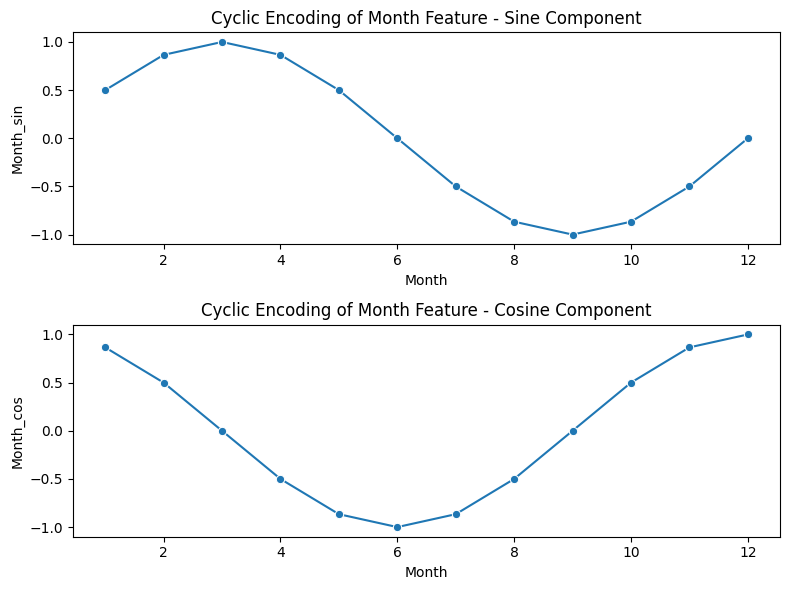

In [52]:
#Plot cyclic encoding
plt.figure(figsize=(8,6))
plt.subplot(2,1,1)
sns.lineplot(x='Month', y='Month_sin', data=df_cyclic_encoding, marker='o')
plt.title('Cyclic Encoding of Month Feature - Sine Component')
plt.subplot(2,1,2)
sns.lineplot(x='Month', y='Month_cos', data=df_cyclic_encoding, marker='o')
plt.title('Cyclic Encoding of Month Feature - Cosine Component')
plt.tight_layout()
plt.show()

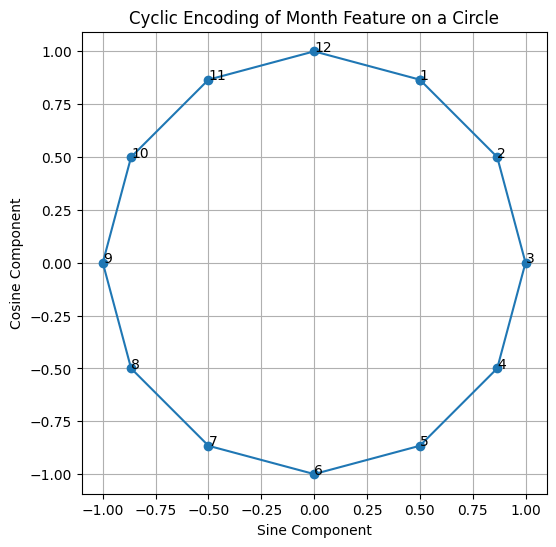

In [53]:
import matplotlib.pyplot as plt

# assume df_cyclic_encoding has columns: Month, Month_sin, Month_cos
n = len(df_cyclic_encoding)

# create x,y and append the first point to close the polygon
x = df_cyclic_encoding['Month_sin'].tolist()
y = df_cyclic_encoding['Month_cos'].tolist()
x.append(x[0])
y.append(y[0])

plt.figure(figsize=(6,6))
plt.plot(x, y, marker='o', linestyle='-')   # now the last point connects to the first
# annotate only the original points (not the duplicated closing point)
for i in range(n):
    plt.text(df_cyclic_encoding['Month_sin'].iat[i],
             df_cyclic_encoding['Month_cos'].iat[i],
             str(df_cyclic_encoding['Month'].iat[i]))

plt.title('Cyclic Encoding of Month Feature on a Circle')
plt.xlabel('Sine Component')
plt.ylabel('Cosine Component')
plt.axis('equal')
plt.grid(True)
plt.show()

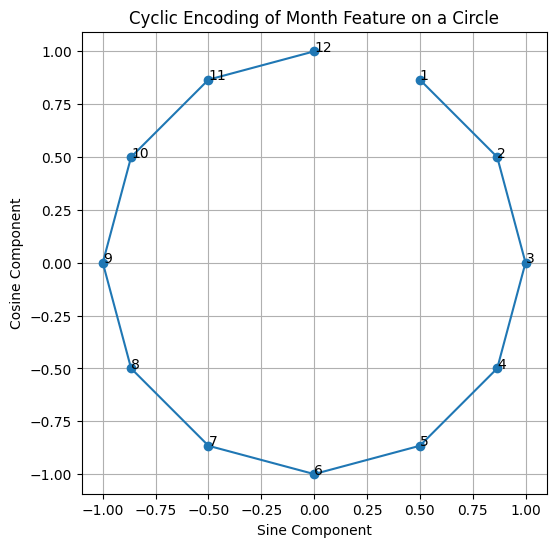

In [54]:
#Plot cyclic encoding on a circle
plt.figure(figsize=(6,6))
plt.plot(df_cyclic_encoding['Month_sin'], df_cyclic_encoding['Month_cos'], marker='o')
for i in range(len(df_cyclic_encoding)):
    plt.text(df_cyclic_encoding['Month_sin'][i], df_cyclic_encoding['Month_cos'][i], str(df_cyclic_encoding['Month'][i]))
plt.title('Cyclic Encoding of Month Feature on a Circle')
plt.xlabel('Sine Component')
plt.ylabel('Cosine Component')
plt.axis('equal')
plt.grid()
plt.show()

# Binning

In [55]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df=iris.data
df['label']=iris.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [56]:
df['sepal_length_binned']=pd.cut(df['sepal length (cm)'], 3)
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label,sepal_length_binned
0,5.1,3.5,1.4,0.2,0,"(4.296, 5.5]"
1,4.9,3.0,1.4,0.2,0,"(4.296, 5.5]"
2,4.7,3.2,1.3,0.2,0,"(4.296, 5.5]"
3,4.6,3.1,1.5,0.2,0,"(4.296, 5.5]"
4,5.0,3.6,1.4,0.2,0,"(4.296, 5.5]"
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,"(5.5, 6.7]"
146,6.3,2.5,5.0,1.9,2,"(5.5, 6.7]"
147,6.5,3.0,5.2,2.0,2,"(5.5, 6.7]"
148,6.2,3.4,5.4,2.3,2,"(5.5, 6.7]"


In [57]:
#show different bins
df['sepal_length_binned'].unique()

[(4.296, 5.5], (5.5, 6.7], (6.7, 7.9]]
Categories (3, interval[float64, right]): [(4.296, 5.5] < (5.5, 6.7] < (6.7, 7.9]]

# Visual Normality Checks

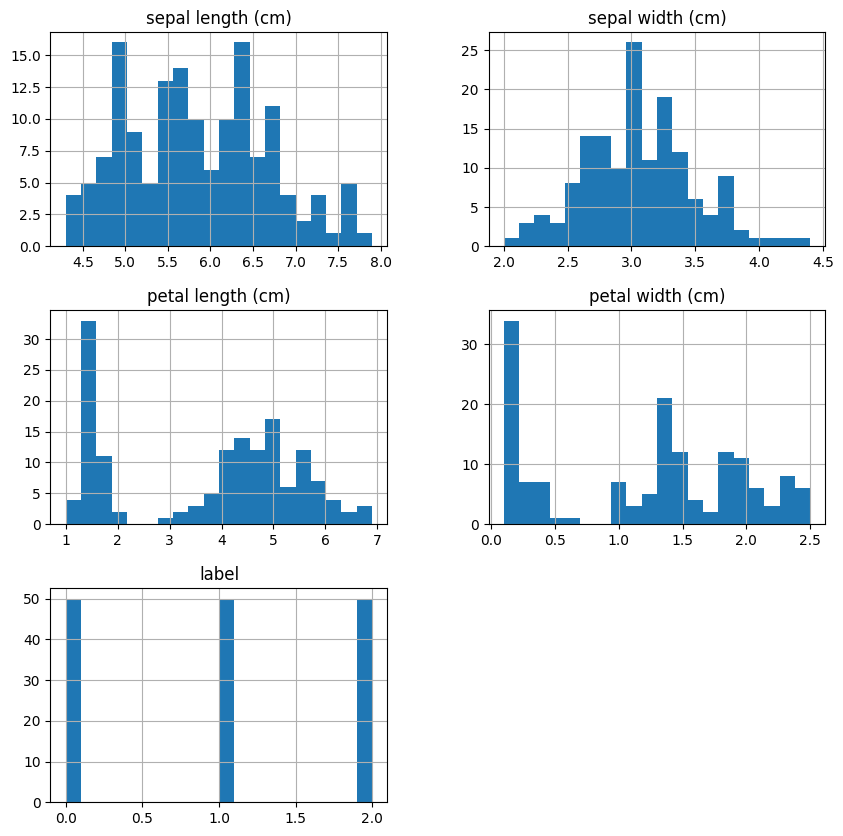

In [58]:
# histogram plot
hist = df.hist(bins=20,figsize=(10, 10))

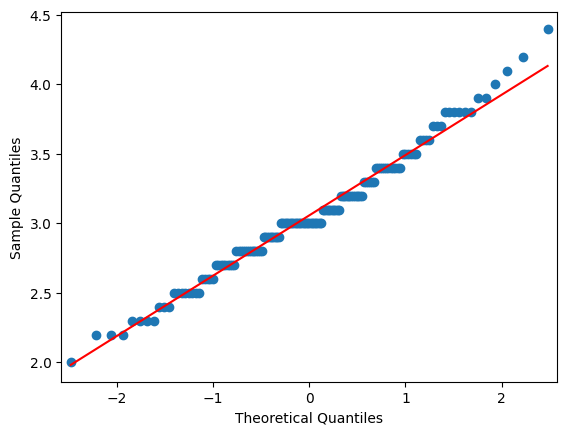

In [59]:
#Quantile-Quantile Plot
# QQ Plot
from statsmodels.graphics.gofplots import qqplot
from matplotlib import pyplot
qqplot(df['sepal width (cm)'], line='s')
pyplot.show()

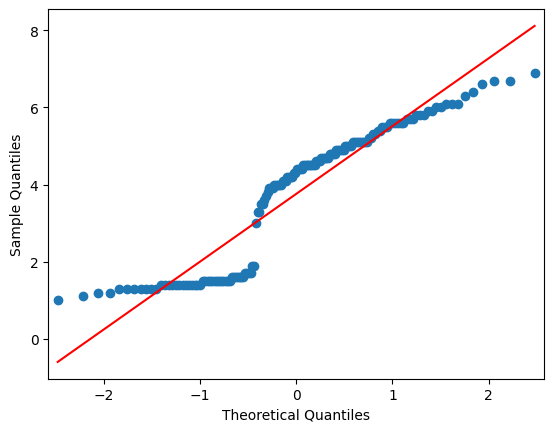

In [60]:
qqplot(df['petal length (cm)'], line='s')
pyplot.show()

# Statistical Skew and Normality Checks

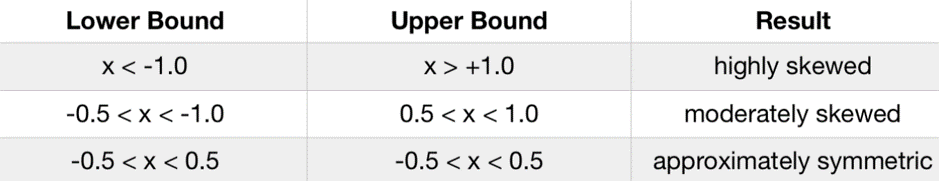

In [61]:
df['sepal length (cm)'].skew()

np.float64(0.3149109566369728)

In [62]:
df['petal length (cm)'].skew()

np.float64(-0.27488417975101276)

In [63]:
# Shapiro-Wilk Test
from scipy.stats import shapiro

def shapiro_wilk_test(data,alpha):
    stat, p = shapiro(data)
    print('Statistics=%.3f, p=%.5f' % (stat, p))
    # interpret
    if p > alpha:
        print('Sample looks Gaussian (fail to reject H0)')
    else:
        print('Sample does not look Gaussian (reject H0)')

shapiro_wilk_test(df['sepal length (cm)'],0.05)       

Statistics=0.976, p=0.01018
Sample does not look Gaussian (reject H0)


In [64]:
shapiro_wilk_test(df['petal length (cm)'],0.05)

Statistics=0.876, p=0.00000
Sample does not look Gaussian (reject H0)


# Transform to normal distribution - Quantile Transformer

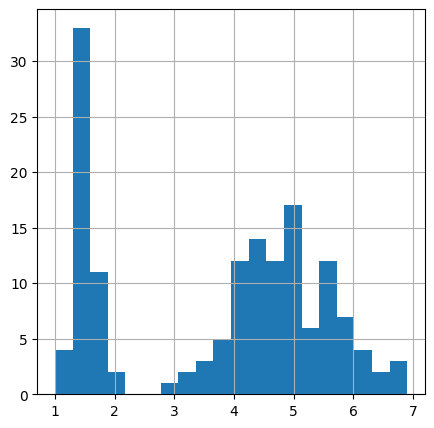

In [65]:
hist = df['petal length (cm)'].hist(bins=20,figsize=(5, 5))

<Axes: >

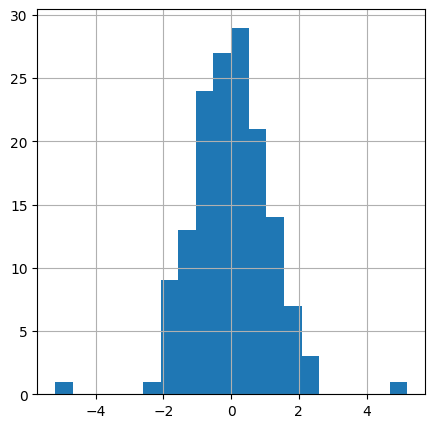

In [66]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(n_quantiles=25, output_distribution='normal',random_state=0)
trans_x=qt.fit_transform(np.array(df['petal length (cm)'].array.reshape(-1, 1)))

df['petal length (cm) qtransformed']=trans_x

df['petal length (cm) qtransformed'].hist(bins=20,figsize=(5, 5))

In [67]:
# even after quantile transformer does not pass SW test
shapiro_wilk_test(df['petal length (cm) qtransformed'],0.05)

Statistics=0.949, p=0.00003
Sample does not look Gaussian (reject H0)


array([[<Axes: title={'center': '0'}>]], dtype=object)

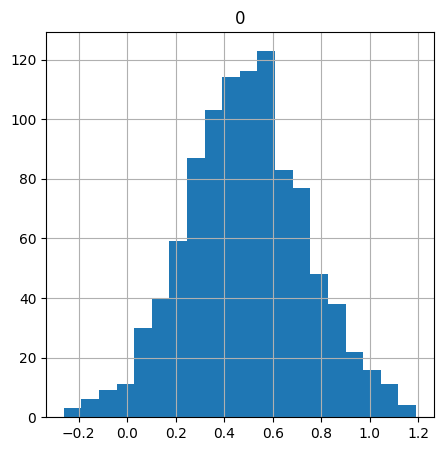

In [68]:
#let's build a normal distribution which passes the test
rng = np.random.RandomState(0)
x = np.sort(rng.normal(loc=0.5, scale=0.25, size=(1000, 1)), axis=0)
df_new=pd.DataFrame(x)
df_new.hist(bins=20,figsize=(5, 5))

In [69]:
shapiro_wilk_test(df_new,0.05)

Statistics=0.999, p=0.59123
Sample looks Gaussian (fail to reject H0)


# Transform to normal distribution - Power Transformation

<Axes: >

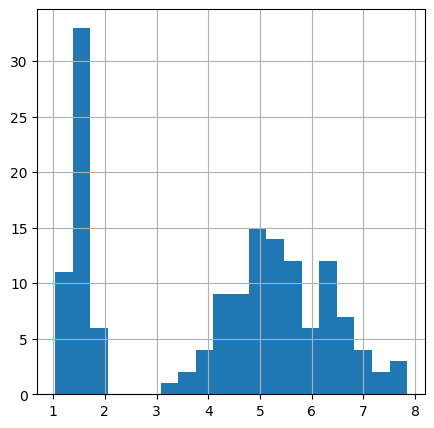

In [70]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(standardize=False)
trans_x= pt.fit_transform(np.array(df['petal length (cm)'].array.reshape(-1, 1)))

df['petal length (cm) ptransformed']=trans_x

df['petal length (cm) ptransformed'].hist(bins=20,figsize=(5, 5))
#Does not work in this example - skew is not clear enough

array([[<Axes: title={'center': '0'}>]], dtype=object)

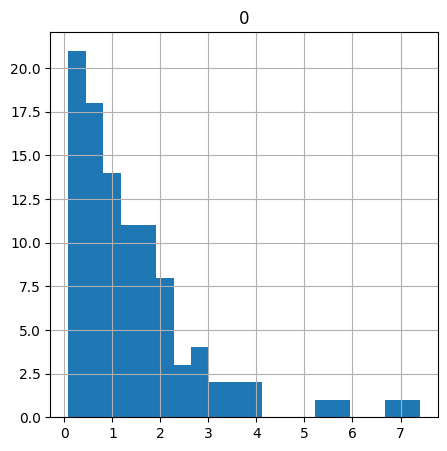

In [71]:
#create a dataset with clearer skew
x_lognormal = np.random.RandomState(916).lognormal(size=(100,1))
df_new=pd.DataFrame(x_lognormal)
df_new.hist(bins=20,figsize=(5, 5))

<Axes: >

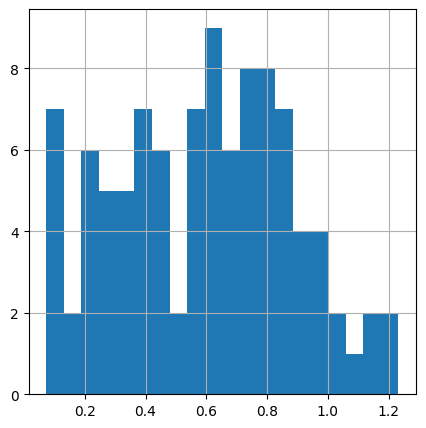

In [72]:
trans_x= pt.fit_transform(np.array(df_new))

df_new['ptransformed']=trans_x

df_new['ptransformed'].hist(bins=20,figsize=(5, 5))